# EJERCICIO LIMPIEZA DE DATOS

Usando el conjunto de datos compartido por el IFE Data Hub sobre abandono escolar (nuestro caso de estudio), favor de programar las siguientes tareas para preprocesar dichos datos:

1. Verificar el número de registros y columnas.
2. Verificar valores nulos por columna.
3. Obtener el resumen de estadísticos (numéricos y categóricos).
4. Contar valores únicos por columna.
5. Explorar los valores únicos de la variable "Gender" y homologar los valores utilizando el comando startswith.
6. Explorar los valores únicos de la variables "TEC.NO.TEC", eliminar los registros con valores que no sean texto y contar el número de registros que contengan este valor.
7. Graficar la variable Edad, utilizando la librería de su preferencia: seaborn o matplotlib.
8. Eliminar los valores anómalos (fuera de rango) de la variable Edad utilizando condicional.


In [ ]:
!pip install numpy
!pip install pandas
!pip install seaborn
!pip install openpyxl


[notice] A new release of pip is available: 23.1.2 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.1.2 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.1.2 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.1.2 -> 24.2
[notice] To update, run: python.exe -m pip install --upgrade pip


# LIBRERIAS

In [ ]:
import numpy as np #Librería que permite manejar variables numéricas.
import pandas as pd #librería de pandas nos permite leer el dataset en forma de dataframe (en forma de tabla)
import seaborn as sns
pd.set_option('display.max_columns', None) #Permite que se visualicen todas las columnas del dataframe

# LECTURA DEL DATASET

In [ ]:
df = pd.read_excel('Dropout_dataset_Case_study.xlsx') #si el archivo es csv entonces sería pd.read_csv
df

,student.id,generation,educational.model,level,gender,age,max.degree.parents,father.education.complete,father.education.summary,mother.education.complete,mother.education.summary,parents.exatec,father.exatec,mother.exatec,tec.no.tec,foreign,zone.type,first.generation,school,program,region,PNA,admission.test,online.test,english.evaluation,admission.rubric,general.math.eval,retention,FTE,scholarship.perc,scholarship.type,loan.perc,total.scholarship.loan,school.cost,id.school.origin,socioeconomic.level,social.lag,average.first.period,failed.subject.first.period,dropped.subject.first.period,dropout.semester,physical.education,cultural.diffusion,student.society,total.life.activities,athletic.sports,art.culture,student.society.leadership,life.work.mentoring,wellness.activities
0,35260,AD16,0,Undergraduate,Female,19,No information,No information,No information,No information,No information,No,No,No,TEC,Local,No information,No information,EIC,IMT,RCS,83.93,Does not apply,0,6,NaN,74.5,1,1.08,0.00,No scholarship,0.00,0.000000,High cost,School 5319,No information,No information,NaN,NaN,NaN,0,1,1,0,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply
1,49405,AD18,0,Undergraduate,Female,18,PhD,Received PhD,PhD,Received master degree,Master degree,Yes,Yes,No,TEC,Local,No information,No,ECSG,LED,RM,86.86,1201,0,7,NaN,82,1,1.08,0.90,Child of Professor/Employee/Director,0.00,0.900002,High cost,School 7371,No information,No information,NaN,NaN,NaN,0,Does not apply,Does not apply,Does not apply,2,1,1,0,0,0
2,106944,AD18,0,High School,Female,15,Undergraduate degree,Received undergraduate degree,Undergraduate degree,Graduated from elementary or middle school,No degree,No,No,No,NO TEC,Local,No information,Does not apply,High school,PTM,RM,89.00,955,0,0,23.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,High cost,School 120,No information,No information,NaN,NaN,NaN,0,Does not apply,Does not apply,Does not apply,2,0,1,1,0,0
3,107183,AD19,1,High School,Male,16,Undergraduate degree,"Attended university, but did not graduate",No degree,Received undergraduate degree,Undergraduate degree,No,No,No,NO TEC,Local,Urban,Does not apply,High school,PTM,RM,96.00,1320,0,6,38.0,Does not apply,1,1.00,0.40,Academic talent,0.00,0.400000,High cost,School 1098,No information,No information,96.666667,0.0,0.0,0,Does not apply,Does not apply,Does not apply,2,1,0,1,0,0
4,92225,AD18,0,Undergraduate,Male,19,Undergraduate degree,Received undergraduate degree,Undergraduate degree,Received undergraduate degree,Undergraduate degree,No,No,No,TEC,Local,No information,No,EN,LAF,RCM,74.60,Does not apply,0,7,NaN,71,0,1.08,0.00,No scholarship,0.00,0.000000,High cost,School 5325,No information,No information,NaN,NaN,NaN,4,Does not apply,Does not apply,Does not apply,2,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,47597,AD20,1,High School,MALE,14,No degree,Graduated from high school,No degree,"Attended university, but did not graduate",No degree,No,No,No,NO TEC,Yes: National,No information,Does not apply,High school,PBB,RCS,90.00,1110,0,2,21.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,Low cost,School 2543,No information,No information,92.333333,0.0,0.0,0,Does not apply,Does not apply,Does not apply,2,0,0,1,0,1
4996,31689,AD14,0,High School,FEMALE,16,Master degree,Received master degree,Master degree,Received master degree,Master degree,Yes,Yes,No,NO TEC,Local,No information,Does not apply,High school,PTM,RM,92.50,1255,0,0,21.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,High cost,School 3213,No information,No information,NaN,NaN,NaN,0,1,0,1,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply
4997,48023,AD14,0,Undergraduate,Male,18,No information,No information,No information,No information,No information,No i

In [ ]:
df.shape #Número de registros, Número de columnas

(5000, 50)

In [ ]:
df.columns #Nombres de las columnas

Index(['student.id', 'generation', 'educational.model', 'level', 'gender',
       'age', 'max.degree.parents', 'father.education.complete',
       'father.education.summary', 'mother.education.complete',
       'mother.education.summary', 'parents.exatec', 'father.exatec',
       'mother.exatec', 'tec.no.tec', 'foreign', 'zone.type',
       'first.generation', 'school', 'program', 'region', 'PNA',
       'admission.test', 'online.test', 'english.evaluation',
       'admission.rubric', 'general.math.eval', 'retention', 'FTE',
       'scholarship.perc', 'scholarship.type', 'loan.perc',
       'total.scholarship.loan', 'school.cost', 'id.school.origin',
       'socioeconomic.level', 'social.lag', 'average.first.period',
       'failed.subject.first.period', 'dropped.subject.first.period',
       'dropout.semester', 'physical.education', 'cultural.diffusion',
       'student.society', 'total.life.activities', 'athletic.sports',
       'art.culture', 'student.society.leadership', 'life.work

In [ ]:
df.info() #RESUMEN EN UN COMANDO de número de columnas, nombre de columna, número de registros no nulos, tipo de dato.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 50 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   student.id                    5000 non-null   int64  
 1   generation                    5000 non-null   object 
 2   educational.model             5000 non-null   int64  
 3   level                         5000 non-null   object 
 4   gender                        5000 non-null   object 
 5   age                           5000 non-null   int64  
 6   max.degree.parents            5000 non-null   object 
 7   father.education.complete     5000 non-null   object 
 8   father.education.summary      5000 non-null   object 
 9   mother.education.complete     5000 non-null   object 
 10  mother.education.summary      5000 non-null   object 
 11  parents.exatec                5000 non-null   object 
 12  father.exatec                 5000 non-null   object 
 13  mot

In [ ]:
df.isna().sum() #NÚMERO DE REGISTROS NULOS POR COLUMNA

student.id                         0
generation                         0
educational.model                  0
level                              0
gender                             0
age                                0
max.degree.parents                 0
father.education.complete          0
father.education.summary           0
mother.education.complete          0
mother.education.summary           0
parents.exatec                     0
father.exatec                      0
mother.exatec                      0
tec.no.tec                         0
foreign                            0
zone.type                          0
first.generation                   0
school                             0
program                            0
region                             0
PNA                                0
admission.test                    67
online.test                        0
english.evaluation                 0
admission.rubric                1203
general.math.eval                  0
r

# RESUMEN DE ESTADÍSTICOS

In [ ]:
df.describe() #describe las variables que toma como numéricas por default y nos permite revisar si están en el formato correcto.
#Si una variable contiene dos tipos de datos los tomará como objeto ejemplo= datos numéricos +  registros con texto.
#También se muestran las variables que son binarias (Valores 0 y 1) como la variable educational.model

,student.id,educational.model,age,PNA,online.test,english.evaluation,admission.rubric,retention,FTE,scholarship.perc,loan.perc,total.scholarship.loan,average.first.period,failed.subject.first.period,dropped.subject.first.period,dropout.semester
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,3797.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,1554.000000,1554.000000,1554.000000,5000.000000
mean,60994.021200,0.310800,17.338000,88.242354,0.010400,3.524400,32.804846,0.920800,1.024400,0.178298,0.035900,0.214198,87.266536,0.169884,0.011583,0.225400
std,34653.540186,0.462867,16.016937,6.084773,0.101459,2.809018,9.451646,0.270078,0.103149,0.232458,0.088982,0.260732,11.388472,0.612780,0.196216,0.837338
min,20.000000,0.000000,0.000000,69.000000,0.000000,0.000000,0.000000,0.000000,0.080000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,31798.500000,0.000000,15.000000,84.000000,0.000000,0.000000,26.000000,1.000000,1.000000,0.000000,0.000000,0.000000,84.000000,0.000000,0.000000,0.000000
50%,60969.500000,0.000000,17.000000,88.485000,0.000000,5.000000,34.000000,1.000000,1.000000,0.000000,0.000000,0.000000,89.666667,0.000000,0.000000,0.000000
75%,90825.500000,1.000000,18.000000,93.000000,0.000000,6.000000,40.000000,1.000000,1.080000,0.400000,0.000000,0.400000,93.666667,0.000000,0.000000,0.000000
max,121523.000000,1.000000,999.000000,100.000000,1.000000,7.000000,50.000000,1.000000,1.420000,0.900000,0.450000,0.900050,100.000000,8.000000,6.000000,4.000000


In [ ]:
df.describe(include=[object]) #Variables que toma como categóricas

,generation,level,gender,max.degree.parents,father.education.complete,father.education.summary,mother.education.complete,mother.education.summary,parents.exatec,father.exatec,mother.exatec,tec.no.tec,foreign,zone.type,first.generation,school,program,region,admission.test,general.math.eval,scholarship.type,school.cost,id.school.origin,socioeconomic.level,social.lag,physical.education,cultural.diffusion,student.society,total.life.activities,athletic.sports,art.culture,student.society.leadership,life.work.mentoring,wellness.activities
count,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,4933,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000,5000
unique,7,2,6,5,9,5,9,5,3,3,3,3,3,4,4,7,71,5,641,246,11,6,1853,8,4,4,4,4,8,4,4,4,4,4
top,AD19,Undergraduate,Male,Undergraduate degree,Received undergraduate degree,Undergraduate degree,Received undergraduate degree,Undergraduate degree,No,No,No,NO TEC,Local,No information,Does not apply,High school,PBB,RM,Does not apply,Does not apply,No scholarship,High cost,School 5325,No information,No information,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply
freq,777,2739,2458,1846,1741,1741,1847,1847,3274,3388,3647,3475,4068,3532,2261,2261,1351,1285,893,2261,2447,2369,124,4345,4142,2278,2278,2278,2722,2722,2722,2722,2722,2722


# VALORES ÚNICOS

In [ ]:
#Aunque en el comando df.describe para las variables categóricas se muestran los valores únicos también es posible mostrarlo para todas las variables

df.nunique() #Cuenta el número total de valores distintos que tiene una variable.

student.id                      4966
generation                         7
educational.model                  2
level                              2
gender                             6
age                               47
max.degree.parents                 5
father.education.complete          9
father.education.summary           5
mother.education.complete          9
mother.education.summary           5
parents.exatec                     3
father.exatec                      3
mother.exatec                      3
tec.no.tec                         3
foreign                            3
zone.type                          4
first.generation                   4
school                             7
program                           71
region                             5
PNA                             1162
admission.test                   641
online.test                        2
english.evaluation                 8
admission.rubric                  43
general.math.eval                246
r

In [ ]:
#Para enumerar los valores únicos de una variable utilizar "[]" y unique

df["gender"].unique() #mostrará los distintos valores en forma de arreglo, también incluye los nan

array(['Female', 'Male', 'M', 'F', 'MALE', 'FEMALE'], dtype=object)

In [ ]:
#EN ESTE CASO PODEMOS VER QUE LA VARIABLE GENDER TIENE DISTINTOS VALORES QUE SIGNIFICAN LO MISMO.

df.loc[df['gender'].str.startswith('F'), 'gender'] = 'Female'

df.loc[df['gender'].str.startswith('M'), 'gender'] = 'Male'


In [ ]:
df["gender"].unique() #los valores ya fueron sustituidos

array(['Female', 'Male'], dtype=object)

In [ ]:
#REVISEMOS LA VARIABLE TEC Y NO TEC

df["tec.no.tec"].unique()  #se observa que existe un valor numérico.

array(['TEC', 'NO TEC', 999], dtype=object)

In [ ]:
#Contar el número de registros que tienen 999
vartec=df[df['tec.no.tec'] == 999].index
len(vartec)

85

In [ ]:
#Eliminar los 85 registros que tienen el valor de 999 en la variable tec.no.tec

df.drop(vartec , inplace=True)

In [ ]:
df

,student.id,generation,educational.model,level,gender,age,max.degree.parents,father.education.complete,father.education.summary,mother.education.complete,mother.education.summary,parents.exatec,father.exatec,mother.exatec,tec.no.tec,foreign,zone.type,first.generation,school,program,region,PNA,admission.test,online.test,english.evaluation,admission.rubric,general.math.eval,retention,FTE,scholarship.perc,scholarship.type,loan.perc,total.scholarship.loan,school.cost,id.school.origin,socioeconomic.level,social.lag,average.first.period,failed.subject.first.period,dropped.subject.first.period,dropout.semester,physical.education,cultural.diffusion,student.society,total.life.activities,athletic.sports,art.culture,student.society.leadership,life.work.mentoring,wellness.activities
0,35260,AD16,0,Undergraduate,Female,19,No information,No information,No information,No information,No information,No,No,No,TEC,Local,No information,No information,EIC,IMT,RCS,83.93,Does not apply,0,6,NaN,74.5,1,1.08,0.00,No scholarship,0.00,0.000000,High cost,School 5319,No information,No information,NaN,NaN,NaN,0,1,1,0,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply
1,49405,AD18,0,Undergraduate,Female,18,PhD,Received PhD,PhD,Received master degree,Master degree,Yes,Yes,No,TEC,Local,No information,No,ECSG,LED,RM,86.86,1201,0,7,NaN,82,1,1.08,0.90,Child of Professor/Employee/Director,0.00,0.900002,High cost,School 7371,No information,No information,NaN,NaN,NaN,0,Does not apply,Does not apply,Does not apply,2,1,1,0,0,0
2,106944,AD18,0,High School,Female,15,Undergraduate degree,Received undergraduate degree,Undergraduate degree,Graduated from elementary or middle school,No degree,No,No,No,NO TEC,Local,No information,Does not apply,High school,PTM,RM,89.00,955,0,0,23.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,High cost,School 120,No information,No information,NaN,NaN,NaN,0,Does not apply,Does not apply,Does not apply,2,0,1,1,0,0
3,107183,AD19,1,High School,Male,16,Undergraduate degree,"Attended university, but did not graduate",No degree,Received undergraduate degree,Undergraduate degree,No,No,No,NO TEC,Local,Urban,Does not apply,High school,PTM,RM,96.00,1320,0,6,38.0,Does not apply,1,1.00,0.40,Academic talent,0.00,0.400000,High cost,School 1098,No information,No information,96.666667,0.0,0.0,0,Does not apply,Does not apply,Does not apply,2,1,0,1,0,0
4,92225,AD18,0,Undergraduate,Male,19,Undergraduate degree,Received undergraduate degree,Undergraduate degree,Received undergraduate degree,Undergraduate degree,No,No,No,TEC,Local,No information,No,EN,LAF,RCM,74.60,Does not apply,0,7,NaN,71,0,1.08,0.00,No scholarship,0.00,0.000000,High cost,School 5325,No information,No information,NaN,NaN,NaN,4,Does not apply,Does not apply,Does not apply,2,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,47597,AD20,1,High School,Male,14,No degree,Graduated from high school,No degree,"Attended university, but did not graduate",No degree,No,No,No,NO TEC,Yes: National,No information,Does not apply,High school,PBB,RCS,90.00,1110,0,2,21.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,Low cost,School 2543,No information,No information,92.333333,0.0,0.0,0,Does not apply,Does not apply,Does not apply,2,0,0,1,0,1
4996,31689,AD14,0,High School,Female,16,Master degree,Received master degree,Master degree,Received master degree,Master degree,Yes,Yes,No,NO TEC,Local,No information,Does not apply,High school,PTM,RM,92.50,1255,0,0,21.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,High cost,School 3213,No information,No information,NaN,NaN,NaN,0,1,0,1,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply
4997,48023,AD14,0,Undergraduate,Male,18,No information,No information,No information,No information,No information,No i

In [ ]:
#REVISEMOS LA VARIABLE TEC Y NO TEC NUEVAMENTE

df["tec.no.tec"].unique()

array(['TEC', 'NO TEC'], dtype=object)

<Axes: xlabel='age'>

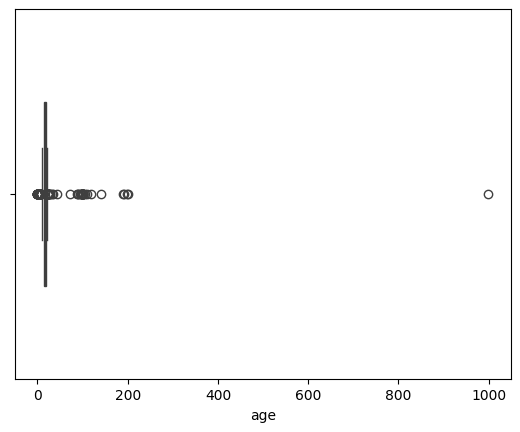

In [ ]:
#VARIABLE EDAD

sns.boxplot(x=df["age"],width=.5)


In [ ]:
#CON LA GRÁFICA SE PUEDE OBSERVAR QUE EXISTEN VALORES OUTLIERS DE EDAD

edades=df["age"].value_counts().sort_index() #frecuencia de cada valor de la variable AGE
edades

age
0         9
1         4
2         6
3         3
4         4
5         2
6         2
7         2
8         5
9         3
11        1
14      433
15     1380
16      393
17      540
18     1539
19      443
20       71
21       21
22        9
23        7
24        2
25        1
26        1
27        2
32        1
34        1
43        1
72        1
88        1
90        2
95        1
96        1
97        1
98        1
99        6
100       4
101       2
105       1
110       1
119       1
140       1
190       1
191       1
199       1
200       1
999       1
Name: count, dtype: int64

In [ ]:
#ELEGIMOS ELIMINAR LOS VALORES MENORES A 14 Y MAYORES A 24 UTILIZANDO FILTROS

df=df[(df['age'] >= 14) & (df['age'] <=24 )]
df




,student.id,generation,educational.model,level,gender,age,max.degree.parents,father.education.complete,father.education.summary,mother.education.complete,mother.education.summary,parents.exatec,father.exatec,mother.exatec,tec.no.tec,foreign,zone.type,first.generation,school,program,region,PNA,admission.test,online.test,english.evaluation,admission.rubric,general.math.eval,retention,FTE,scholarship.perc,scholarship.type,loan.perc,total.scholarship.loan,school.cost,id.school.origin,socioeconomic.level,social.lag,average.first.period,failed.subject.first.period,dropped.subject.first.period,dropout.semester,physical.education,cultural.diffusion,student.society,total.life.activities,athletic.sports,art.culture,student.society.leadership,life.work.mentoring,wellness.activities
0,35260,AD16,0,Undergraduate,Female,19,No information,No information,No information,No information,No information,No,No,No,TEC,Local,No information,No information,EIC,IMT,RCS,83.93,Does not apply,0,6,NaN,74.5,1,1.08,0.00,No scholarship,0.00,0.000000,High cost,School 5319,No information,No information,NaN,NaN,NaN,0,1,1,0,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply
1,49405,AD18,0,Undergraduate,Female,18,PhD,Received PhD,PhD,Received master degree,Master degree,Yes,Yes,No,TEC,Local,No information,No,ECSG,LED,RM,86.86,1201,0,7,NaN,82,1,1.08,0.90,Child of Professor/Employee/Director,0.00,0.900002,High cost,School 7371,No information,No information,NaN,NaN,NaN,0,Does not apply,Does not apply,Does not apply,2,1,1,0,0,0
2,106944,AD18,0,High School,Female,15,Undergraduate degree,Received undergraduate degree,Undergraduate degree,Graduated from elementary or middle school,No degree,No,No,No,NO TEC,Local,No information,Does not apply,High school,PTM,RM,89.00,955,0,0,23.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,High cost,School 120,No information,No information,NaN,NaN,NaN,0,Does not apply,Does not apply,Does not apply,2,0,1,1,0,0
3,107183,AD19,1,High School,Male,16,Undergraduate degree,"Attended university, but did not graduate",No degree,Received undergraduate degree,Undergraduate degree,No,No,No,NO TEC,Local,Urban,Does not apply,High school,PTM,RM,96.00,1320,0,6,38.0,Does not apply,1,1.00,0.40,Academic talent,0.00,0.400000,High cost,School 1098,No information,No information,96.666667,0.0,0.0,0,Does not apply,Does not apply,Does not apply,2,1,0,1,0,0
4,92225,AD18,0,Undergraduate,Male,19,Undergraduate degree,Received undergraduate degree,Undergraduate degree,Received undergraduate degree,Undergraduate degree,No,No,No,TEC,Local,No information,No,EN,LAF,RCM,74.60,Does not apply,0,7,NaN,71,0,1.08,0.00,No scholarship,0.00,0.000000,High cost,School 5325,No information,No information,NaN,NaN,NaN,4,Does not apply,Does not apply,Does not apply,2,1,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,47597,AD20,1,High School,Male,14,No degree,Graduated from high school,No degree,"Attended university, but did not graduate",No degree,No,No,No,NO TEC,Yes: National,No information,Does not apply,High school,PBB,RCS,90.00,1110,0,2,21.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,Low cost,School 2543,No information,No information,92.333333,0.0,0.0,0,Does not apply,Does not apply,Does not apply,2,0,0,1,0,1
4996,31689,AD14,0,High School,Female,16,Master degree,Received master degree,Master degree,Received master degree,Master degree,Yes,Yes,No,NO TEC,Local,No information,Does not apply,High school,PTM,RM,92.50,1255,0,0,21.0,Does not apply,1,1.00,0.00,No scholarship,0.00,0.000000,High cost,School 3213,No information,No information,NaN,NaN,NaN,0,1,0,1,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply,Does not apply
4997,48023,AD14,0,Undergraduate,Male,18,No information,No information,No information,No information,No information,No i

In [ ]:
edades_filtradas = df["age"].value_counts().sort_index() #frecuencia de cada valor de la variable AGE
edades_filtradas

age
14     433
15    1380
16     393
17     540
18    1539
19     443
20      71
21      21
22       9
23       7
24       2
Name: count, dtype: int64

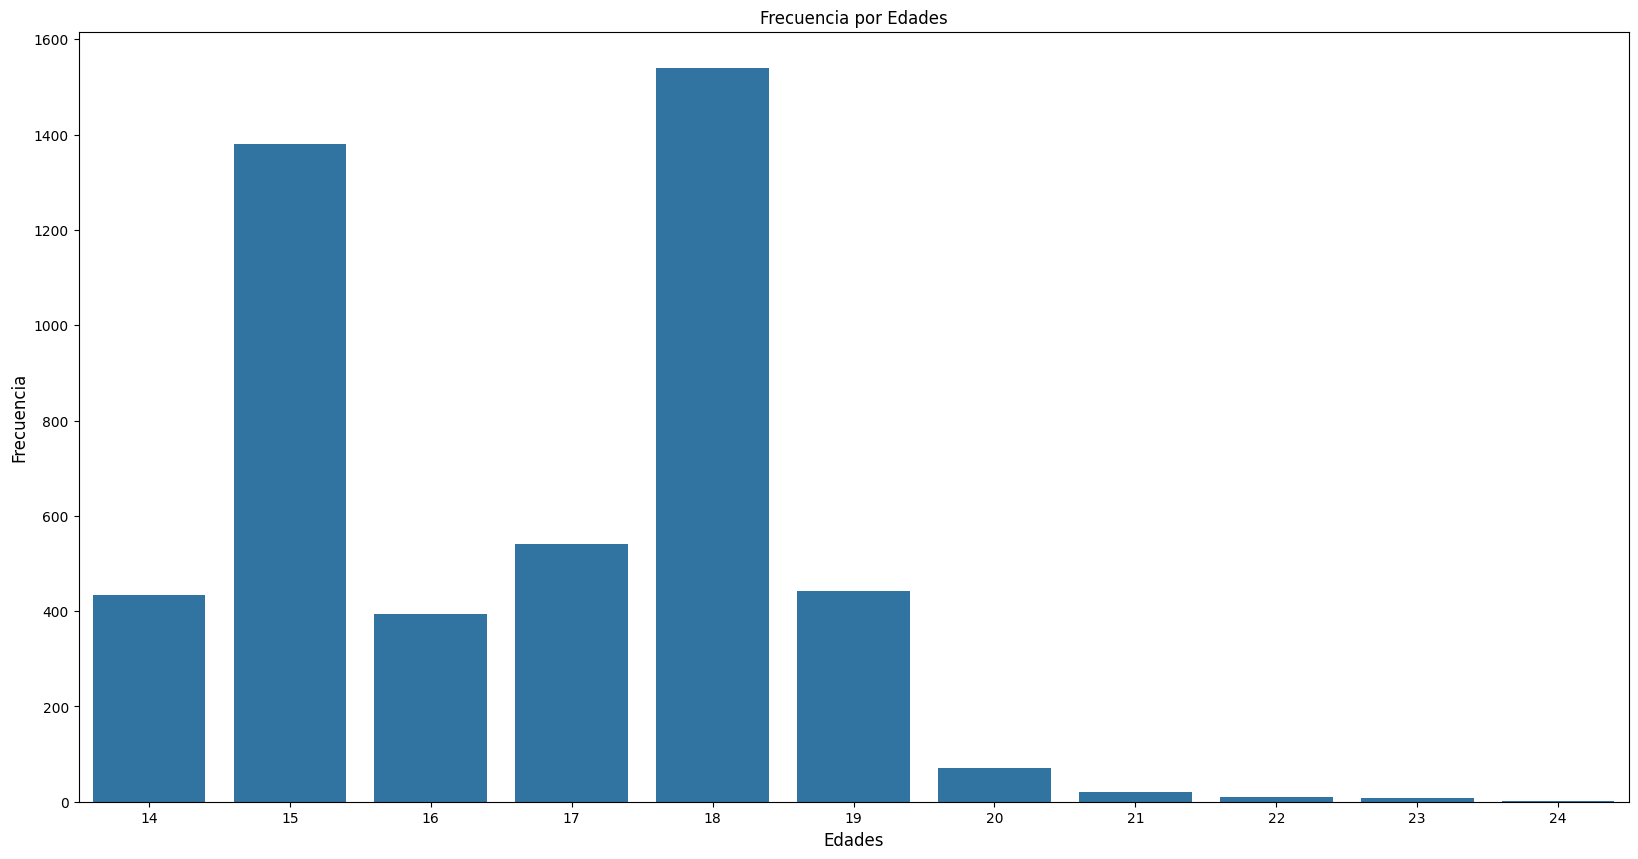

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(20,10))

sns.barplot(edades_filtradas)
plt.title('Frecuencia por Edades')
plt.ylabel('Frecuencia', fontsize=12)
plt.xlabel('Edades', fontsize=12)
plt.show()